# 07 — Model Evaluation and Research Experiments (FD001)

**Project:** Predictive Intelligence · **Phase 9, part 1**

## Objective

Notebooks 05 and 06 produced headline numbers. This notebook stress-tests them. A result is only worth reporting if we know how much it moves when something reasonable changes. Five experiments:

1. **Seed sensitivity** — how much does a result change from the random seed alone?
2. **Hyperparameter tuning** — does a systematic search (Optuna) improve on the default settings by more than that noise?
3. **Ablation** — which groups of features is the model actually getting its accuracy from?
4. **Sensitivity** — what happens to predictions when sensors get noisier, or one sensor stops responding?
5. **Error analysis** — which engines does the model get wrong, and is there a pattern?

All experiments use the working model (XGBoost on the Phase 4 features, decision D-013). Generalisation to the other three subsets is in the next notebook.

**Experiment tracking.** Each run is logged with MLflow: its settings, its metrics, and a name. MLflow is a logbook for experiments, so that months later we can still answer "which settings produced that number?". Runs are stored locally in `mlflow.db` (not in Git) and can be browsed with `mlflow ui --backend-store-uri sqlite:///mlflow.db`.

**Use of the test set.** Tuning and ablation decisions are made by cross-validation only. The test set is used to *report* seed variation and robustness, never to choose a setting.

> **Data note.** C-MAPSS is simulated turbofan data, not telemetry from real aircraft.

## 1. Setup

In [1]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")   # optional notebook progress-bar widget

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src import config
from src.data.cmapss import SENSOR_INFO, add_training_rul, load_subset
from src.data.splits import engine_folds
from src.evaluation.metrics import mae, nasa_score, rmse
from src.features.build import build_tabular_features, cap_rul
from src.visualization import theme

theme.apply_theme()
warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# MLflow keeps its records in a small local database file (not in Git).
mlflow.set_tracking_uri(f"sqlite:///{(project_root / 'mlflow.db').as_posix()}")
mlflow.set_experiment("fd001-evaluation")

CAP = config.RUL_CAP
sensors = config.FD001_SENSORS
train, test, test_rul = load_subset("FD001")
train_table, feature_columns = build_tabular_features(
    add_training_rul(train), sensors, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
train_table["target"] = cap_rul(train_table["rul"], CAP)


def last_rows_with_features(test_frame: pd.DataFrame) -> pd.DataFrame:
    table, _ = build_tabular_features(test_frame, sensors, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
    return table.groupby("engine_id").tail(1).merge(test_rul, on="engine_id")


test_last = last_rows_with_features(test)
true_rul = test_last["true_rul"].to_numpy()

DEFAULT_PARAMS = dict(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8)


def make_xgb(seed: int = config.RANDOM_SEED, **overrides) -> XGBRegressor:
    return XGBRegressor(**{**DEFAULT_PARAMS, **overrides}, n_jobs=-1, random_state=seed)


def cv_rmse(make_model, features=None) -> tuple[float, float]:
    # Mean and spread of engine-wise 5-fold validation RMSE against the capped label.
    features = features or feature_columns
    scores = []
    for train_rows, validation_rows in engine_folds(train_table):
        fold_train, fold_validation = train_table.iloc[train_rows], train_table.iloc[validation_rows]
        model = make_model().fit(fold_train[features], fold_train["target"])
        scores.append(rmse(fold_validation["target"], np.clip(model.predict(fold_validation[features]), 0, CAP)))
    return float(np.mean(scores)), float(np.std(scores))


def test_metrics(model, rows: pd.DataFrame | None = None) -> dict:
    rows = test_last if rows is None else rows
    predicted = np.clip(model.predict(rows[feature_columns]), 0, CAP)
    return {"test_rmse": rmse(true_rul, predicted), "test_mae": mae(true_rul, predicted),
            "test_nasa_score": nasa_score(true_rul, predicted)}


def log_run(name: str, params: dict, metrics: dict) -> None:
    with mlflow.start_run(run_name=name):
        mlflow.log_params(params)
        mlflow.log_metrics({key: float(value) for key, value in metrics.items()})

## 2. Seed sensitivity

Both tree models use randomness: which rows and features each tree sees. The **random seed** fixes those choices so a run can be repeated. A different seed gives a slightly different model.

Notebook 05 reported one run per model. Before reading anything into a difference of a cycle or so, we need to know how much one model differs *from itself* under different seeds. Each model is trained five times on all 100 training engines, changing nothing but the seed.

In [2]:
seed_rows = []
for seed in range(5):
    for name, model in [
        ("XGBoost", make_xgb(seed)),
        ("Random Forest", RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.33,
                                                n_jobs=-1, random_state=seed)),
    ]:
        model.fit(train_table[feature_columns], train_table["target"])
        metrics = test_metrics(model)
        seed_rows.append({"model": name, "seed": seed, **metrics})
        log_run(f"seed-{name}-{seed}", {"model": name, "seed": seed, "experiment": "seed sensitivity"}, metrics)

seed_results = pd.DataFrame(seed_rows)
seed_summary = seed_results.groupby("model")[["test_rmse", "test_nasa_score"]].agg(["mean", "std", "min", "max"])
seed_summary.round(2)

test_rmse                     test_nasa_score                 \
                   mean   std    min    max            mean    std     min   
model                                                                        
Random Forest     13.85  0.06  13.78  13.93          265.06   2.06  262.70   
XGBoost           14.78  0.29  14.30  15.08          304.66  17.18  277.69   

                       
                  max  
model                  
Random Forest  267.28  
XGBoost        323.82

**Findings.**

- **Random Forest is very stable**: test RMSE 13.85 with a spread of 0.06 across seeds (13.78 to 13.93). Averaging 300 trees leaves little room for chance.
- **XGBoost moves more**: 14.78 with a spread of 0.29 (14.30 to 15.08). Its NASA score ranges from 278 to 324, a swing of about 15% from the seed alone.
- **The single XGBoost run reported in notebook 05 (15.11) was at the unlucky end.** Its typical value is closer to 14.8. That is a useful reminder of why one run is not enough.
- **The gap between the two models is real on this test set**: about 0.9 cycles, roughly three times XGBoost's seed spread. Cross-validation had them level (13.1 against 13.3), so the honest summary is: Random Forest is slightly but consistently better on these 100 test engines, and the two are equivalent on held-out training engines.

**Rule adopted for the rest of the project:** a difference in test RMSE smaller than about 0.5 cycles between two XGBoost configurations is treated as noise.

## 3. Hyperparameter tuning with Optuna

**Hyperparameters** are the settings chosen *before* training: how many trees, how deep, how fast to learn. So far we have used common default values.

**Optuna** searches for better ones. It tries a setting, records how well it did, and uses the results so far to choose more promising settings next (a strategy called TPE, which concentrates trials where good results have been found). This is far more efficient than trying every combination.

**How each trial is scored.** By 5-fold cross-validation on whole engines, exactly as in notebook 05. The test set plays no part.

**Is it worth doing?** Only if the gain is clearly larger than the noise measured in section 2. Tuning has a real risk: with enough trials, some setting will look best on these particular folds by luck. So the tuned model must also be judged on the test set, over several seeds.

**When not to tune.** When data is so limited that the validation estimate is itself noisy (the spread across our folds is close to one cycle), fine differences between settings are not trustworthy.

The search covers seven settings over 25 trials.

In [3]:
def objective(trial: optuna.Trial) -> float:
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 200, 800, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 6),
        min_child_weight=trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
    )
    mean_rmse, spread = cv_rmse(lambda: make_xgb(**params))
    trial.set_user_attr("fold_spread", spread)
    log_run(f"optuna-trial-{trial.number}", {**params, "experiment": "tuning"}, {"cv_rmse": mean_rmse, "cv_rmse_sd": spread})
    return mean_rmse


started = time.perf_counter()
# The search is stored on disk, so re-running the notebook reuses finished trials instead of repeating them.
N_TRIALS = 25
study = optuna.create_study(
    study_name="fd001-xgboost", direction="minimize", load_if_exists=True,
    storage=f"sqlite:///{(project_root / 'experiments' / 'optuna_fd001.db').as_posix()}",
    sampler=optuna.samplers.TPESampler(seed=config.RANDOM_SEED))
finished = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
study.optimize(objective, n_trials=max(0, N_TRIALS - len(finished)))
tuning_minutes = sum((t.datetime_complete - t.datetime_start).total_seconds() for t in study.trials if t.datetime_complete) / 60

default_cv, default_cv_spread = cv_rmse(make_xgb)
best_params = study.best_params
print(f"Search time: {tuning_minutes:.1f} minutes for {len([t for t in study.trials if t.value is not None])} completed trials")
print(f"Default settings: CV RMSE {default_cv:.2f} (fold spread {default_cv_spread:.2f})")
print(f"Best trial:       CV RMSE {study.best_value:.2f} (fold spread {study.best_trial.user_attrs['fold_spread']:.2f})")
print("Best settings:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in best_params.items()})

Search time: 18.9 minutes for 25 completed trials
Default settings: CV RMSE 13.30 (fold spread 0.74)
Best trial:       CV RMSE 13.14 (fold spread 0.74)
Best settings: {'n_estimators': 800, 'learning_rate': 0.011, 'max_depth': 5, 'min_child_weight': 1.671, 'subsample': 0.619, 'colsample_bytree': 0.949, 'reg_lambda': 1.495}


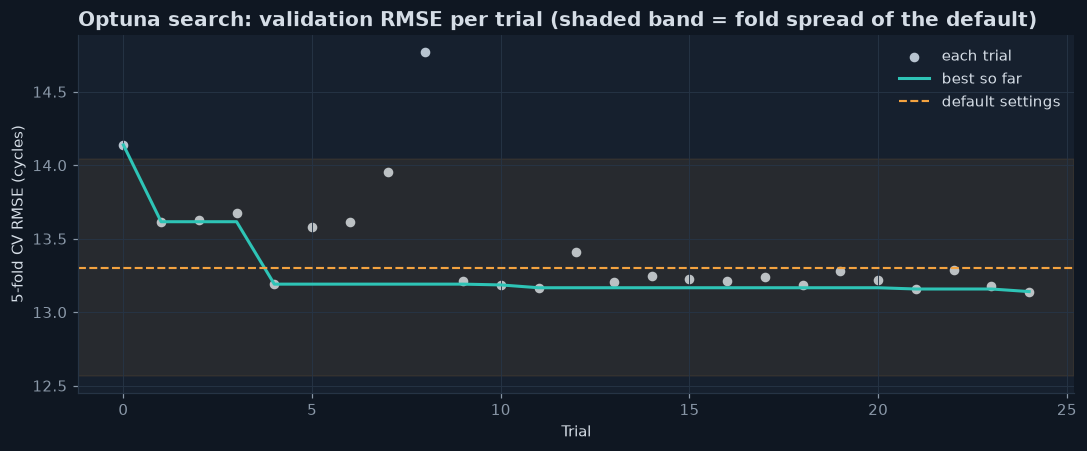

In [4]:
trial_values = pd.Series([t.value for t in study.trials if t.value is not None])

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.scatter(trial_values.index, trial_values, color=theme.SILVER, s=28, label="each trial")
ax.plot(trial_values.index, trial_values.cummin(), color=theme.TEAL, linewidth=2, label="best so far")
ax.axhline(default_cv, color=theme.AMBER, linestyle="--", linewidth=1.4, label="default settings")
ax.axhspan(default_cv - default_cv_spread, default_cv + default_cv_spread, color=theme.AMBER, alpha=0.08)
ax.set_title("Optuna search: validation RMSE per trial (shaded band = fold spread of the default)")
ax.set_xlabel("Trial")
ax.set_ylabel("5-fold CV RMSE (cycles)")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

### The honest test: tuned against default on the test set

Both configurations are trained with the same five seeds and scored on the test set. The tuned settings were fixed by cross-validation before this cell ran.

In [5]:
comparison_rows = []
for seed in range(5):
    for label, model in [("default", make_xgb(seed)), ("tuned", make_xgb(seed, **best_params))]:
        model.fit(train_table[feature_columns], train_table["target"])
        comparison_rows.append({"settings": label, "seed": seed, **test_metrics(model)})

tuned_comparison = pd.DataFrame(comparison_rows)
tuned_summary = tuned_comparison.groupby("settings")[["test_rmse", "test_mae", "test_nasa_score"]].agg(["mean", "std"])
tuned_summary.insert(0, ("cv_rmse", ""), [default_cv, study.best_value])
log_run("tuned-vs-default", {"experiment": "tuning summary", **best_params},
        {"default_cv_rmse": default_cv, "tuned_cv_rmse": study.best_value,
         "default_test_rmse_mean": tuned_summary.loc["default", ("test_rmse", "mean")],
         "tuned_test_rmse_mean": tuned_summary.loc["tuned", ("test_rmse", "mean")]})

(project_root / "experiments" / "fd001_xgboost_tuned_params.json").write_text(json.dumps(best_params, indent=1))
tuned_summary.round(2)

cv_rmse test_rmse       test_mae       test_nasa_score       
                      mean   std     mean   std            mean    std
settings                                                              
default    13.30     14.78  0.29    10.81  0.15          304.66  17.18
tuned      13.14     14.42  0.12    10.37  0.10          296.00   3.84

**Findings.**

- **In cross-validation the search gained 0.16 cycles** (13.30 to 13.14). The spread between folds is 0.74, so by itself this is far too small to count as an improvement.
- **On the test set the tuned settings are a little better and steadier**: 14.42 against 14.78, with a seed spread of 0.12 against 0.29. The gain of about 0.36 cycles is a little over one seed-spread of the default model, and below the 0.5-cycle rule set in section 2. MAE improves from 10.8 to 10.4 and the NASA score from 305 to 296.
- **What the search found** is a familiar pattern: more trees (800) with a much lower learning rate (0.011) and slightly deeper trees. Slower, more gradual learning usually gives a smoother model, which fits the lower seed spread.
- **Cost:** about 19 minutes of computation for a gain of a third of a cycle.

**Verdict: Optuna added a small, real-looking improvement in stability and a marginal one in accuracy. It did not change any conclusion.** The tuned model still does not catch Random Forest (13.85). On a dataset of 100 engines, the choice of features (section 4) matters about ten times more than the choice of hyperparameters.

**What we do with it.** The tuned settings are saved in `experiments/fd001_xgboost_tuned_params.json` and can be used with `python scripts/train.py --params ...`. The served model keeps the default settings, because the explainability and uncertainty analyses in notebooks 08 and 09 were carried out on it and the difference does not justify redoing them.

**Caveat.** Twenty-five trials is a short search. The best trial was chosen on the same folds it was scored on, so its cross-validation figure is slightly optimistic; the test comparison above is the fair one.

## 4. Ablation: where does the accuracy come from?

An **ablation study** removes one part of a system at a time and measures what is lost. The size of the loss shows how much that part was contributing. It is the experimental counterpart of the SHAP analysis in notebook 08: SHAP says what the model *uses*; ablation says what it *needs*.

The model has four kinds of feature for each sensor. Each kind is removed in turn, the model is retrained, and it is scored by cross-validation with default settings.

In [6]:
feature_groups = {
    "current reading": [f for f in feature_columns if f in sensors],
    "30-cycle average": [f for f in feature_columns if "_mean" in f],
    "30-cycle variability": [f for f in feature_columns if "_std" in f],
    "change from baseline": [f for f in feature_columns if f.endswith("_delta")],
}

ablation_rows = {"all features": {"features": len(feature_columns), "CV RMSE": default_cv, "fold spread": default_cv_spread}}
for group, columns in feature_groups.items():
    kept = [f for f in feature_columns if f not in columns]
    mean_rmse, spread = cv_rmse(make_xgb, kept)
    ablation_rows[f"without {group}"] = {"features": len(kept), "CV RMSE": mean_rmse, "fold spread": spread}
    log_run(f"ablation-without-{group}", {"experiment": "ablation", "removed": group}, {"cv_rmse": mean_rmse})

for group, columns in feature_groups.items():
    mean_rmse, spread = cv_rmse(make_xgb, columns)
    ablation_rows[f"only {group}"] = {"features": len(columns), "CV RMSE": mean_rmse, "fold spread": spread}
    log_run(f"ablation-only-{group}", {"experiment": "ablation", "kept": group}, {"cv_rmse": mean_rmse})

ablation = pd.DataFrame(ablation_rows).T
ablation["change vs all features"] = ablation["CV RMSE"] - default_cv
ablation.round(2)

,features,CV RMSE,fold spread,change vs all features
all features,56.0,13.30,0.74,0.00
without current reading,42.0,13.41,0.74,0.10
without 30-cycle average,42.0,13.58,0.41,0.28
without 30-cycle variability,42.0,13.67,0.86,0.37
without change from baseline,42.0,17.04,1.00,3.74
only current reading,14.0,18.65,1.13,5.35
only 30-cycle average,14.0,22.43,1.31,9.13
only 30-cycle variability,14.0,25.59,1.23,12.29
only change from baseline,14.0,15.65,0.61,2.34


**Findings.**

- **Change from baseline is the one group the model cannot do without.** Removing it raises the error from 13.3 to 17.0, a loss of 3.7 cycles. Removing any other group costs 0.1 to 0.4 cycles, which is within the fold spread and cannot be distinguished from no loss.
- **Used alone, change from baseline reaches 15.7**, within 2.4 cycles of the full model using a quarter of the features. No other group comes close: the current readings alone give 18.7, the 30-cycle average alone 22.4, and the variability alone 25.6.
- **The other three groups are largely interchangeable.** Each can be dropped with little effect because the remaining groups carry similar information. Together they still add something: the full model beats change-from-baseline alone by 2.3 cycles.
- One result is unexpected: the 30-cycle average alone (22.4) does worse than the unsmoothed current reading alone (18.7). A likely reason is that a smoothed raw level still contains the engine's own starting level, which notebook 03 showed to be a large source of variation, while being slower to react than the raw reading. This is an interpretation, not something this experiment tested.

**This agrees with the SHAP analysis** in notebook 08, where about half of all contribution came from the change-from-baseline features. Two different methods, one that looks inside the model and one that removes its inputs, point to the same conclusion: knowing each engine's own starting point is the most valuable thing this pipeline does.

**Practical consequence.** The model depends on the engine's first 20 flights being on record. For an engine whose monitoring began mid-life, the expected error is nearer 17 cycles than 13.

## 5. Sensitivity: noisier sensors and a sensor that stops responding

A model that is accurate only on clean inputs is fragile. Two realistic disturbances are applied to the **test** readings, and the model (trained once on clean data, default settings) is scored again. Nothing is tuned here; this is a measurement.

**Extra sensor noise.** Random noise is added to every sensor, sized as a multiple of that sensor's own healthy noise from notebook 03. "×1" means the noise level is roughly doubled in variance terms. Each level is repeated with five different random draws.

**One sensor stops responding.** For each sensor in turn, its readings over the engine's last 30 cycles are replaced by the engine's own early-life average, as if the sensor had frozen at a healthy value. This is a dangerous failure: the sensor looks plausible and reports "no wear".

In [7]:
final_model = make_xgb().fit(train_table[feature_columns], train_table["target"])
clean_metrics = test_metrics(final_model)
clean_prediction = np.clip(final_model.predict(test_last[feature_columns]), 0, CAP)

# Healthy noise per sensor: spread of the first 30 cycles around each engine's own mean (as in notebook 03).
early = train[train["cycle"] <= 30]
healthy_noise = (early[sensors] - early.groupby("engine_id")[sensors].transform("mean")).std()

noise_rows = []
for multiple in [0.0, 0.5, 1.0, 2.0]:
    draws = []
    for draw in range(5):
        rng = np.random.default_rng(draw)
        noisy = test.copy()
        noisy[sensors] = noisy[sensors] + rng.normal(0, 1, size=noisy[sensors].shape) * healthy_noise.to_numpy() * multiple
        draws.append(test_metrics(final_model, last_rows_with_features(noisy)))
    draws = pd.DataFrame(draws)
    noise_rows.append({"added noise (× healthy noise)": multiple, "test RMSE": draws["test_rmse"].mean(),
                       "RMSE sd over draws": draws["test_rmse"].std(), "NASA score": draws["test_nasa_score"].mean()})
    log_run(f"noise-x{multiple}", {"experiment": "sensitivity", "noise_multiple": multiple},
            {"test_rmse": draws["test_rmse"].mean()})

pd.DataFrame(noise_rows).set_index("added noise (× healthy noise)").round(2)

,test RMSE,RMSE sd over draws,NASA score
added noise (× healthy noise),,,
0.0,15.11,0.00,321.87
0.5,16.88,0.42,433.04
1.0,21.31,0.57,805.75
2.0,27.16,0.82,1684.87


Clean test data: RMSE 15.11, late by more than 20: 7


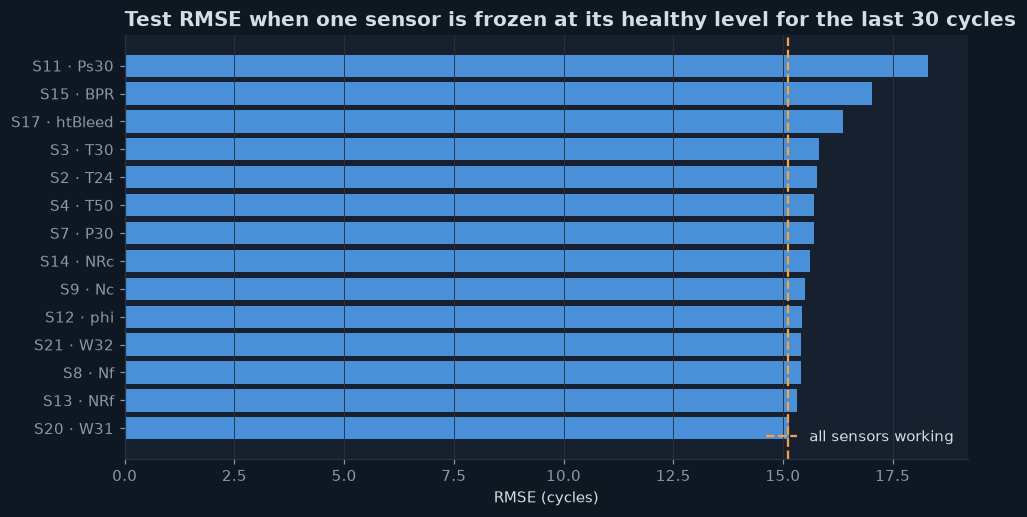

,test RMSE,average change in estimate (cycles),late by more than 20
sensor,,,
S11 · Ps30,18.30,7.95,24
S15 · BPR,17.03,7.46,15
S17 · htBleed,16.36,6.99,13
S3 · T30,15.81,4.31,9
S2 · T24,15.78,4.30,8
S4 · T50,15.71,5.25,11
S7 · P30,15.70,5.39,10
S14 · NRc,15.63,3.32,10
S9 · Nc,15.51,5.28,15


In [8]:
frozen_rows = []
cycles_from_end = test.groupby("engine_id")["cycle"].transform("max") - test["cycle"]
engine_early_mean = test[test["cycle"] <= config.BASELINE_CYCLES].groupby("engine_id")[sensors].mean()

for sensor in sensors:
    frozen = test.copy()
    in_last_30 = cycles_from_end < 30
    frozen.loc[in_last_30, sensor] = frozen.loc[in_last_30, "engine_id"].map(engine_early_mean[sensor])
    rows = last_rows_with_features(frozen)
    predicted = np.clip(final_model.predict(rows[feature_columns]), 0, CAP)
    frozen_rows.append({
        "sensor": f"{sensor.replace('sensor_', 'S')} · {SENSOR_INFO[sensor][0]}",
        "test RMSE": rmse(true_rul, predicted),
        "average change in estimate (cycles)": (predicted - clean_prediction).mean(),
        "late by more than 20": int((predicted - true_rul > 20).sum()),
    })

frozen_table = pd.DataFrame(frozen_rows).set_index("sensor").sort_values("test RMSE", ascending=False)
print(f"Clean test data: RMSE {clean_metrics['test_rmse']:.2f}, late by more than 20: {int((clean_prediction - true_rul > 20).sum())}")

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(frozen_table.index, frozen_table["test RMSE"], color=theme.BLUE)
ax.axvline(clean_metrics["test_rmse"], color=theme.AMBER, linestyle="--", label="all sensors working")
ax.invert_yaxis()
ax.set_title("Test RMSE when one sensor is frozen at its healthy level for the last 30 cycles")
ax.set_xlabel("RMSE (cycles)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

frozen_table.round(2)

**Findings: extra noise.**

- The model is sensitive to noisier sensors. Adding half the healthy noise raises test RMSE from 15.1 to 16.9. Adding as much noise again as is already there raises it to 21.3, and the NASA score more than doubles (322 to 806). At twice the healthy noise the error reaches 27.
- This follows from notebook 03: the wear signal is only a few noise-widths in size, so there is not much margin.

**Findings: one sensor frozen at a healthy level.**

- **Every frozen sensor makes the model more optimistic.** The average estimate rises by 2 to 8 cycles, whichever sensor is frozen. That is the dangerous direction: the engine looks healthier than it is.
- **Losing S11 (Ps30) is the worst case.** RMSE rises from 15.1 to 18.3 and the number of engines predicted late by more than 20 cycles goes from 7 to 24, about a quarter of the fleet. This is the sensor SHAP identified as the model's main source.
- S15 (bypass ratio), S17 (bleed enthalpy) and S9 (core speed) follow, each roughly doubling the number of badly late predictions.
- The model degrades gradually, not catastrophically, because the wear signal is spread across many sensors. But it gives **no warning**: it simply returns a more optimistic number.

**What this means for a real system.** A frozen or drifting sensor is a foreseeable fault, and this model cannot detect one by itself. Any deployment would need separate checks on the health of the sensors before their readings reach the model, and the monitoring in Phase 12 is a first step towards that. The assistant must never present a prediction as if the inputs were known to be sound.

**Caveat.** These are two simple, artificial disturbances applied to simulated data. Real sensor faults take many forms (bias, drift, spikes, dropouts) that were not tested.

## 6. Error analysis

Finally, a closer look at where the working model is wrong on the test set. Error = predicted − true, so positive is late.

In [9]:
analysis = test_last[["engine_id", "cycle", "true_rul"]].rename(columns={"cycle": "cycles_recorded"}).copy()
analysis["predicted"] = clean_prediction
analysis["error"] = analysis["predicted"] - analysis["true_rul"]
analysis["abs_error"] = analysis["error"].abs()
within_cap = analysis["true_rul"] <= CAP

overall = pd.Series({
    "mean error, all engines": analysis["error"].mean(),
    "mean error, true RUL within the cap": analysis.loc[within_cap, "error"].mean(),
    "median absolute error": analysis["abs_error"].median(),
    "share within ±10 cycles (%)": (analysis["abs_error"] <= 10).mean() * 100,
    "share within ±20 cycles (%)": (analysis["abs_error"] <= 20).mean() * 100,
    "late predictions (%)": (analysis["error"] > 0).mean() * 100,
    "rank correlation: abs error vs cycles recorded": analysis["abs_error"].corr(analysis["cycles_recorded"], method="spearman"),
    "rank correlation: abs error vs true RUL": analysis["abs_error"].corr(analysis["true_rul"], method="spearman"),
    "rank correlation: predicted vs true RUL": analysis["predicted"].corr(analysis["true_rul"], method="spearman"),
})
overall.round(2).to_frame("value")

,value
"mean error, all engines",-1.90
"mean error, true RUL within the cap",0.55
median absolute error,7.33
share within ±10 cycles (%),60.00
share within ±20 cycles (%),82.00
late predictions (%),54.00
rank correlation: abs error vs cycles recorded,-0.26
rank correlation: abs error vs true RUL,0.55
rank correlation: predicted vs true RUL,0.88


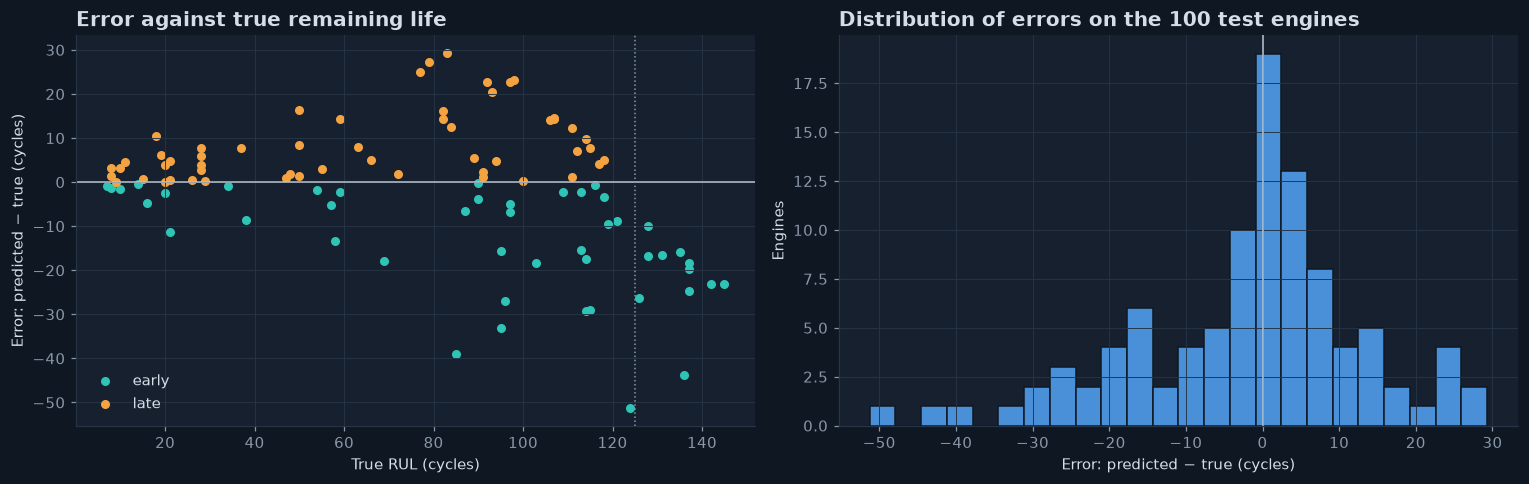

,engines,mean_true_rul,mean_abs_error,mean_error
cycles_recorded,,,,
31-80,23,112.4,13.9,3.8
81-130,22,87.4,11.6,0.7
131-180,38,63.0,8.2,-3.2
181+,17,38.2,11.6,-10.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
late = analysis["error"] > 0
axes[0].scatter(analysis.loc[~late, "true_rul"], analysis.loc[~late, "error"], color=theme.TEAL, s=24, label="early")
axes[0].scatter(analysis.loc[late, "true_rul"], analysis.loc[late, "error"], color=theme.AMBER, s=24, label="late")
axes[0].axhline(0, color=theme.SILVER, linewidth=1)
axes[0].axvline(CAP, color=theme.MUTED, linestyle=":", linewidth=1)
axes[0].set_title("Error against true remaining life")
axes[0].set_xlabel("True RUL (cycles)")
axes[0].set_ylabel("Error: predicted − true (cycles)")
axes[0].legend(loc="lower left")

axes[1].hist(analysis["error"], bins=24, color=theme.BLUE, edgecolor=theme.BACKGROUND)
axes[1].axvline(0, color=theme.SILVER, linewidth=1)
axes[1].set_title("Distribution of errors on the 100 test engines")
axes[1].set_xlabel("Error: predicted − true (cycles)")
axes[1].set_ylabel("Engines")
fig.tight_layout()
plt.show()

history_bands = pd.cut(analysis["cycles_recorded"], bins=[0, 80, 130, 180, 400], labels=["31-80", "81-130", "131-180", "181+"])
analysis.groupby(history_bands, observed=True).agg(
    engines=("error", "size"), mean_true_rul=("true_rul", "mean"),
    mean_abs_error=("abs_error", "mean"), mean_error=("error", "mean")).round(1)

**Findings.**

- **The model ranks engines well.** The rank correlation between predicted and true remaining life is 0.88. For deciding which engines to look at first, this matters more than the exact numbers.
- **Typical accuracy:** the median miss is about 7 cycles; 60% of engines are within 10 cycles and 82% within 20.
- **No overall bias where the model can answer.** For engines whose true RUL is within the cap, the average error is +0.6 cycles. The overall average of −1.9 comes from the engines above the cap, which a capped model must underestimate.
- **Errors grow with remaining life** (rank correlation 0.55 between the size of the error and the true RUL). The model is most accurate close to failure, and the left-hand chart shows the spread widening to the right.
- **Engines with long recorded histories tend to be predicted too early.** For the 17 engines with more than 180 flights on record, the average error is −10 cycles. These are long-lived engines: they have drifted far enough to look worn, but then last longer than a typical training engine did. The error is in the cautious direction, but it would mean inspecting such engines sooner than necessary.
- **About half of predictions are late (54%)**, as expected from an unbiased model. Being unbiased is not the same as being safe: a system used for safety decisions would want fewer late predictions, at the cost of more early ones. The lower end of the range from notebook 09 is the tool for that, not the point estimate.

## 7. Conclusions

| Experiment | Result |
|---|---|
| Seed sensitivity | Random Forest 13.85 ± 0.06; XGBoost 14.78 ± 0.29. Differences under about 0.5 cycles are noise |
| Tuning (Optuna, 25 trials, 19 min) | XGBoost 14.78 to 14.42 on the test set and steadier across seeds; small gain, no change in conclusions |
| Ablation | Removing change-from-baseline costs 3.7 cycles; removing any other feature group costs under 0.4 |
| Extra sensor noise | RMSE 15.1 to 21.3 when the noise level is doubled |
| One frozen sensor | Always makes the estimate more optimistic; S11 frozen puts 24 engines late by more than 20 cycles instead of 7 |
| Error analysis | Rank correlation with the truth 0.88; unbiased within the cap; least accurate for engines with long remaining life |

**What changed in our understanding.**

1. The headline numbers from notebook 05 are sound but should carry their spread: XGBoost is about 14.8 ± 0.3, not exactly 15.1.
2. Feature engineering, and one feature idea in particular, accounts for most of the accuracy. Tuning accounts for very little.
3. The model's main weakness is not accuracy on clean data. It is silent optimism when its inputs degrade.

**Limitations.** Everything here is on FD001 and on one model family. The seed and tuning comparisons use the 100-engine test set, which is small. The disturbances in section 5 are illustrative, not a complete robustness study. All 60 or so runs are logged in MLflow for inspection.

## 8. Next steps

**Notebook 10 - generalisation:** the same recipe on FD002, FD003 and FD004, and models moved between subsets.